In [25]:
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
properties = pd.read_csv("assessments.csv", low_memory=False)

properties.head()

FileNotFoundError: [Errno 2] No such file or directory: 'assessments.csv'

In [28]:
print("Total property records:", len(properties))
print("Number of municipalities:", properties["MUNIDESC"].nunique())
print("Number of assessment areas:", properties["NEIGHDESC"].nunique())

properties[["MUNIDESC", "MUNICODE", "NEIGHDESC", "NEIGHCODE"]].head(15)

NameError: name 'properties' is not defined

In [24]:
properties["CLASSDESC"].value_counts()

NameError: name 'properties' is not defined

In [8]:
residential = properties[
    properties["CLASSDESC"] == "RESIDENTIAL"
].copy()

residential["FAIRMARKETTOTAL"] = pd.to_numeric(
    residential["FAIRMARKETTOTAL"],
    errors="coerce"
)

residential = residential.dropna(
    subset=["FAIRMARKETTOTAL", "MUNIDESC", "NEIGHDESC"]
)

residential = residential[
    residential["FAIRMARKETTOTAL"] > 0
]

print("Residential properties:", len(residential))

NameError: name 'properties' is not defined

In [7]:


area_summary = residential.groupby("NEIGHDESC").agg(
    property_count=("PARID", "count"),
    median_value=("FAIRMARKETTOTAL", "median"),
    average_value=("FAIRMARKETTOTAL", "mean")
).reset_index()


area_summary = area_summary[
    ~area_summary["NEIGHDESC"].astype(str).str.fullmatch(r"\d+")
].copy()


area_summary = area_summary[
    area_summary["property_count"] >= 100
]

area_summary = area_summary.sort_values("median_value")

area_summary.head(40)

,NEIGHDESC,property_count,median_value,average_value
65,2 GARDENS MUNI 926,184,4100.0,14875.543478
262,BRADDOCK BOROUGH,1436,4250.0,13272.555710
436,REDWOOD MOBILE H.P.,286,5850.0,11039.860140
357,JAMES STEVEN MANOR M.H.P..,134,6300.0,9614.925373
88,8 COMPLESEXES - 34 UNITS,115,7000.0,110172.173913
507,VIRGINIA HILLS M.H.P.,334,7250.0,15444.311377
509,WAGNER MOBILE H.P.,115,9800.0,20180.000000
83,51 ESTATES MOBILE H.P.,147,10100.0,14990.476190
291,CLOVERLEAF MOBILE H.P.,482,13500.0,15290.663900
435,RANKIN BOROUGH,725,14100.0,18469.241379


In [8]:


area_summary["NEIGHDESC"] = (
    area_summary["NEIGHDESC"]
    .astype(str)
    .str.strip()
    .str.title()
)


exclude_terms = [
    "Mobile H.P.",
    "Mobile Home",
    "Gardens",
    "Complex",
    "Estates",
    "Manor",
    "Lofts",
    "Towers"
]

area_summary = area_summary[
    ~area_summary["NEIGHDESC"].str.contains(
        "|".join(exclude_terms),
        case=False,
        na=False
    )
].copy()


area_summary = area_summary.sort_values(
    "median_value"
).reset_index(drop=True)

area_summary.head(40)

,NEIGHDESC,property_count,median_value,average_value
0,Braddock Borough,1436,4250.0,13272.555710
1,8 Complesexes - 34 Units,115,7000.0,110172.173913
2,Virginia Hills M.H.P.,334,7250.0,15444.311377
3,Rankin Borough,725,14100.0,18469.241379
4,North Braddock Borough,3096,16000.0,20321.463178
5,Wall Borough,489,16800.0,21152.965235
6,City Of Duquesne,3119,17500.0,21015.982687
7,City Of Mckeesport,10134,20000.0,26335.829090
8,Bluff District Of Pittsburgh,316,20550.0,36333.544304
9,Homestead Borough,1279,20700.0,24064.550430


In [10]:


clean_summary = area_summary.copy()


exclude_terms = (
    "MOBILE",
    "GARDENS",
    "COMPLEX",
    "ESTATES",
    "MANOR",
    "LOFTS",
    "TOWERS"
)

clean_summary = clean_summary[
    ~clean_summary["NEIGHDESC"].str.upper().str.contains(
        "|".join(exclude_terms),
        na=False
    )
].copy()


clean_summary = clean_summary[
    ~clean_summary["NEIGHDESC"].str.fullmatch(r"\d+", na=False)
]


clean_summary = clean_summary[
    clean_summary["property_count"] >= 100
]


clean_summary = clean_summary.sort_values(
    "median_value"
).reset_index(drop=True)


clean_summary.head(40)

,NEIGHDESC,property_count,median_value,average_value
0,Braddock Borough,1436,4250.0,13272.555710
1,8 Complesexes - 34 Units,115,7000.0,110172.173913
2,Virginia Hills M.H.P.,334,7250.0,15444.311377
3,Rankin Borough,725,14100.0,18469.241379
4,North Braddock Borough,3096,16000.0,20321.463178
5,Wall Borough,489,16800.0,21152.965235
6,City Of Duquesne,3119,17500.0,21015.982687
7,City Of Mckeesport,10134,20000.0,26335.829090
8,Bluff District Of Pittsburgh,316,20550.0,36333.544304
9,Homestead Borough,1279,20700.0,24064.550430


In [11]:


exclude_terms = [
    "MOBILE",
    "COMPLEX",
    "GARDENS",
    "ESTATES",
    "MANOR",
    "LOFTS",
    "TOWERS"
]

final_summary = clean_summary[
    ~clean_summary["NEIGHDESC"].str.upper().str.contains(
        "|".join(exclude_terms),
        na=False
    )
].copy()

final_summary = final_summary.sort_values(
    "median_value"
).reset_index(drop=True)

final_summary.head(40)

,NEIGHDESC,property_count,median_value,average_value
0,Braddock Borough,1436,4250.0,13272.555710
1,8 Complesexes - 34 Units,115,7000.0,110172.173913
2,Virginia Hills M.H.P.,334,7250.0,15444.311377
3,Rankin Borough,725,14100.0,18469.241379
4,North Braddock Borough,3096,16000.0,20321.463178
5,Wall Borough,489,16800.0,21152.965235
6,City Of Duquesne,3119,17500.0,21015.982687
7,City Of Mckeesport,10134,20000.0,26335.829090
8,Bluff District Of Pittsburgh,316,20550.0,36333.544304
9,Homestead Borough,1279,20700.0,24064.550430


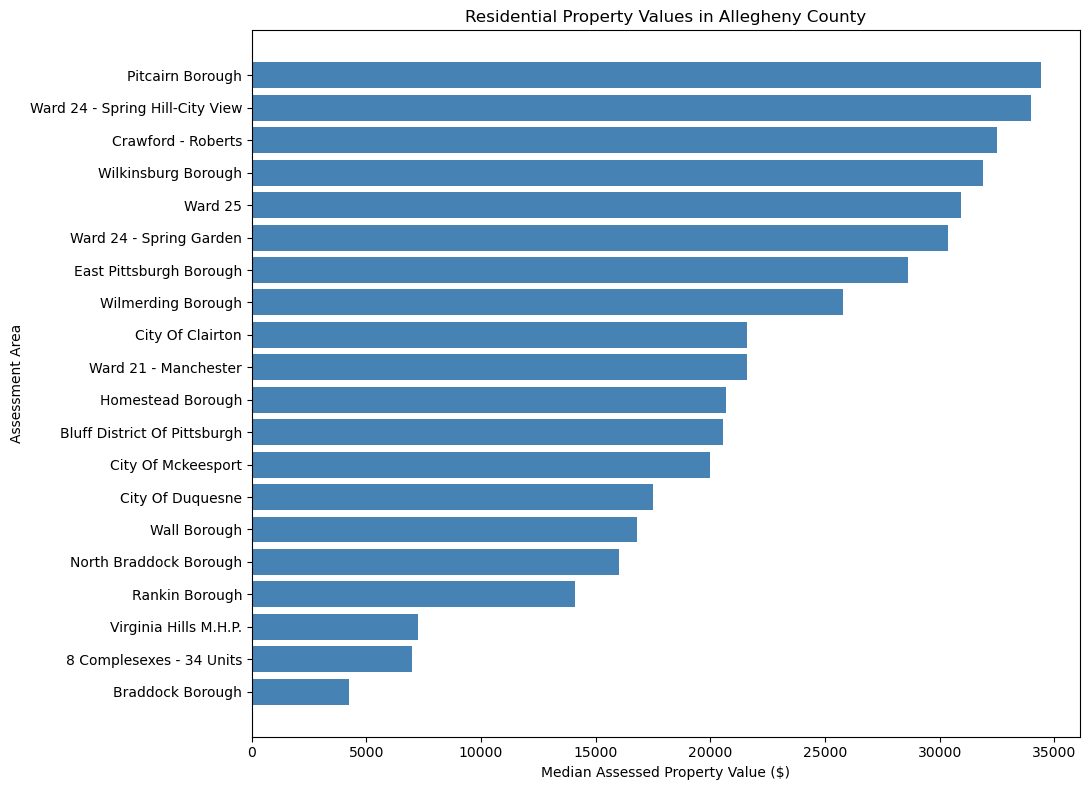

In [12]:
import matplotlib.pyplot as plt

graph_data = final_summary.head(20).sort_values(
    "median_value",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    graph_data["NEIGHDESC"],
    graph_data["median_value"],
    color="steelblue"
)

plt.xlabel("Median Assessed Property Value ($)")
plt.ylabel("Assessment Area")
plt.title("Residential Property Values in Allegheny County")

plt.tight_layout()
plt.show()

In [13]:

final_summary.head(5)

,NEIGHDESC,property_count,median_value,average_value
0,Braddock Borough,1436,4250.0,13272.555710
1,8 Complesexes - 34 Units,115,7000.0,110172.173913
2,Virginia Hills M.H.P.,334,7250.0,15444.311377
3,Rankin Borough,725,14100.0,18469.241379
4,North Braddock Borough,3096,16000.0,20321.463178


In [14]:

final_summary.tail(5).sort_values(
    "median_value",
    ascending=False
)

,NEIGHDESC,property_count,median_value,average_value
133,Trimont Plaza & Marmont,124,360700.0,360148.387097
132,Strip Loft,266,338550.0,355228.233083
131,1000 Grandview,312,337100.0,393578.397436
130,Shadyside,2087,320200.0,368189.507906
129,Bradford Woods Borough,533,253800.0,267837.116323
